# Assignment Beta, Question 1: SaafHawa closed API or self-hosted model
**Student ID:** 23k-0078

Every step is calculated from `model_data.csv` (sources and access dates per model), `tool_latency_log.csv` (raw timings) and the saved Qwen `config.json`. Rerun this notebook whenever the latency log grows.

In [1]:
import json
import math
from pathlib import Path
from statistics import median

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 240, "display.max_columns", 40, "display.max_colwidth", 34)
HERE = Path(".")
results = {}

## Parameters from the roll number

In [2]:
ROLL = "23k-0078"
digits = [int(c) for c in ROLL if c.isdigit()]
R = int(ROLL[-2:])
D = sum(digits) % 10
Q = 1500 + 25 * R
N = 5 + (R % 4)
p = 0.04 + 0.01 * D
H = 4 + (R % 4)
B = 1200 + 10 * R
T = 10 - (R % 3)
print(f"R = {R}; D = ({' + '.join(map(str, digits))}) mod 10 = {sum(digits)} mod 10 = {D}")
print(f"Q = 1500 + 25 x {R} = {Q}")
print(f"N = 5 + ({R} mod 4) = {N}")
print(f"p = 0.04 + 0.01 x {D} = {p:.2f}")
print(f"H = 4 + ({R} mod 4) = {H}")
print(f"B = 1200 + 10 x {R} = ${B}")
print(f"T = 10 - ({R} mod 3) = {T} s")
results["params"] = dict(R=R, D=D, Q=Q, N=N, p=p, H=H, B=B, T=T)

R = 78; D = (2 + 3 + 0 + 0 + 7 + 8) mod 10 = 20 mod 10 = 0
Q = 1500 + 25 x 78 = 3450
N = 5 + (78 mod 4) = 7
p = 0.04 + 0.01 x 0 = 0.04
H = 4 + (78 mod 4) = 6
B = 1200 + 10 x 78 = $1980
T = 10 - (78 mod 3) = 10 s


## Section 2, item 1: token volume
Input for call k is 2,000 + 800(k - 1). Each call outputs 350 tokens, except the final call, which outputs 600. Calls 1 to N - 1 repeat once with probability p, with the same input and another 350 output tokens.

In [3]:
calls = pd.DataFrame({"k": range(1, N + 1)})
calls["input"] = 2000 + 800 * (calls.k - 1)
calls["output"] = [350] * (N - 1) + [600]
calls["retry_prob"] = [p] * (N - 1) + [0.0]
calls["expected_retry_input"] = calls.input * calls.retry_prob
calls["expected_retry_output"] = calls.output * calls.retry_prob
print(calls.to_string(index=False))

first_in, first_out = calls.input.sum(), calls.output.sum()
retry_in, retry_out = calls.expected_retry_input.sum(), calls.expected_retry_output.sum()
I = first_in + retry_in
O = first_out + retry_out
expected_calls = N + (N - 1) * p
print(f"\nExpected input per query = {first_in} + {retry_in:.0f} = {I:.0f}")
print(f"Expected output per query = {first_out} + {retry_out:.0f} = {O:.0f}")
print(f"Expected LLM calls per query = {N} + {N - 1} x {p:.2f} = {expected_calls:.2f}")

normal_days = 30 - H
Qm = normal_days * Q + H * 5 * Q
print(f"\nMonthly queries = {normal_days} x {Q} + {H} x 5 x {Q} = {normal_days * Q:,} + {H * 5 * Q:,} = {Qm:,}")
print(f"Monthly input = {Qm:,} x {I:.0f} = {Qm * I:,.0f}")
print(f"Monthly output = {Qm:,} x {O:.0f} = {Qm * O:,.0f}")
results["tokens"] = dict(I=I, O=O, first_in=int(first_in), first_out=int(first_out), retry_in=retry_in, retry_out=retry_out,
                         expected_calls=expected_calls, Qm=Qm, monthly_in=Qm * I, monthly_out=Qm * O,
                         table=calls.to_dict("records"))

 k  input  output  retry_prob  expected_retry_input  expected_retry_output
 1   2000     350        0.04                  80.0                   14.0
 2   2800     350        0.04                 112.0                   14.0
 3   3600     350        0.04                 144.0                   14.0
 4   4400     350        0.04                 176.0                   14.0
 5   5200     350        0.04                 208.0                   14.0
 6   6000     350        0.04                 240.0                   14.0
 7   6800     600        0.00                   0.0                    0.0

Expected input per query = 30800 + 960 = 31760
Expected output per query = 2700 + 84 = 2784
Expected LLM calls per query = 7 + 6 x 0.04 = 7.24

Monthly queries = 24 x 3450 + 6 x 5 x 3450 = 82,800 + 103,500 = 186,300
Monthly input = 186,300 x 31760 = 5,916,888,000
Monthly output = 186,300 x 2784 = 518,659,200


## Section 2, item 2: monthly API cost
Hidden reasoning tokens are added to output, as the assignment requires. For a model in a reasoning setting:

- If first answer token is later than first token, reasoning tokens per call = (first answer - first token) x output speed.
- If the two figures are equal, the first token is hidden, so the median first-token time of current non-reasoning models replaces it.

These are estimates from benchmark workloads, and SaafHawa's short tool-call steps may use fewer.

**Cache model.** The 1,500-token prefix is read on every call. Cache entries are assumed to go cold once an hour, a deliberately cautious figure at these traffic levels, so 720 writes of 1,500 tokens are charged per month at the write price where one exists. Where the provider states no usable price or its stated minimum may exceed 1,500, caching is off.

In [4]:
models = pd.read_csv(HERE / "model_data.csv")
models["cache_ok"] = models.cache_ok.astype(bool)
PREFIX = 1500
WRITES_PER_MONTH = 720

def monthly_cost(row, queries, input_tokens, output_tokens, n_calls, use_cache):
    output = output_tokens + row.reasoning_tokens_per_call * n_calls
    if not (use_cache and row.cache_ok):
        return queries * (input_tokens * row.pi + output * row.po) / 1e6
    cached = PREFIX * n_calls
    writes = WRITES_PER_MONTH * PREFIX
    write_price = row.pw if pd.notna(row.pw) else row.pc
    cost = queries * ((input_tokens - cached) * row.pi + output * row.po) + (queries * cached - writes) * row.pc + writes * write_price
    return cost / 1e6

rows = []
for _, m in models.iterrows():
    off = monthly_cost(m, Qm, I, O, expected_calls, False)
    on = monthly_cost(m, Qm, I, O, expected_calls, True)
    rows.append(dict(model=m["name"], side=m.side, price_from=m.price_provider, reasoning_per_query=m.reasoning_tokens_per_call * expected_calls,
                     no_cache=off, with_cache=on, within_B_no_cache=off <= B, within_B_cache=on <= B, cache_used=bool(m.cache_ok)))
cost = pd.DataFrame(rows)
print(f"Worked example, {models.iloc[2]['name']} without caching: {Qm:,} x ({I:.0f} x ${models.iloc[2].pi} + {O:.0f} x ${models.iloc[2].po}) / 1e6 = ${cost.iloc[2].no_cache:,.2f}")
print(f"Cached tokens per query = {PREFIX} x {expected_calls:.2f} = {PREFIX * expected_calls:.0f}; uncached = {I - PREFIX * expected_calls:.0f}\n")
print(cost.sort_values("with_cache").round(2).to_string(index=False))
results["cost"] = cost.to_dict("records")

Worked example, GPT-6 Luna without caching: 186,300 x (31760 x $0.1 + 2784 x $0.5) / 1e6 = $851.02
Cached tokens per query = 1500 x 7.24 = 10860; uncached = 20900

                   model   side  price_from  reasoning_per_query  no_cache  with_cache  within_B_no_cache  within_B_cache  cache_used
DeepSeek V4.1 Flash 1017   Open Particle AI                 0.00    277.59      230.04               True            True        True
              GPT-6 Luna Closed      OpenAI                 0.00    851.02      669.05               True            True        True
  Nemotron 3.5 Lightning   Open   Darkbloom             25509.64    780.45      755.16               True            True        True
             Qwen3.8 27B   Open      Chutes                 0.00    879.08      808.07               True            True        True
         Mistral Small 4   Open     Mistral                 0.00   1198.73      925.59               True            True        True
        Claude Haiku 5.5 Closed 

## Section 2, item 3: peak load and rate limits
On a heatwave day traffic is 5Q, and 35% of it arrives in the 120 minutes from 12:00 to 14:00.

In [5]:
heat_day = 5 * Q
window_queries = 0.35 * heat_day
peak_qpm = window_queries / 120
peak_rpm = peak_qpm * expected_calls
peak_in, peak_out = peak_qpm * I, peak_qpm * O
print(f"Heatwave day = 5 x {Q} = {heat_day:,} queries")
print(f"Window = 0.35 x {heat_day:,} = {window_queries:,.1f} queries over 120 minutes")
print(f"Peak queries per minute = {peak_qpm:.2f} ({peak_qpm / 60:.4f} per second)")
print(f"Peak LLM requests per minute = {peak_qpm:.2f} x {expected_calls:.2f} = {peak_rpm:.1f}")
print(f"Peak input TPM = {peak_in:,.0f}; output TPM = {peak_out:,.0f}; total = {peak_in + peak_out:,.0f}")

checks = []
for name, rpm, itpm, otpm, combined in [("Claude Haiku 5.5", 4000, 2000000, 400000, None), ("Claude Sonnet 5.5", 4000, 2000000, 400000, None),
                                        ("GPT-6 Luna", 5000, None, None, 2000000), ("GPT-6.1 Terra", 5000, None, None, 1000000),
                                        ("Nova 2 Lite", 2000, None, None, 8000000), ("Grok 4.7", 9000, None, None, 50000000)]:
    m = models[models.name == name].iloc[0]
    out_tpm = peak_qpm * (O + m.reasoning_tokens_per_call * expected_calls)
    uncached_in = peak_qpm * (I - PREFIX * expected_calls)
    if combined:
        used, limit = peak_in + out_tpm, combined
        ok = peak_rpm <= rpm and used <= limit
        detail = f"{used:,.0f} of {limit:,} TPM"
    else:
        ok = peak_rpm <= rpm and uncached_in <= itpm and out_tpm <= otpm
        detail = f"uncached input {uncached_in:,.0f} of {itpm:,}; output {out_tpm:,.0f} of {otpm:,}"
    checks.append(dict(model=name, rpm_used=round(peak_rpm), rpm_limit=rpm, tokens=detail, fits=bool(ok)))
checks = pd.DataFrame(checks)
print("\n" + checks.to_string(index=False))
results["peak"] = dict(heat_day=heat_day, window_queries=window_queries, peak_qpm=peak_qpm, peak_qps=peak_qpm / 60, peak_rpm=peak_rpm, peak_in=peak_in, peak_out=peak_out, checks=checks.to_dict("records"))

Heatwave day = 5 x 3450 = 17,250 queries
Window = 0.35 x 17,250 = 6,037.5 queries over 120 minutes
Peak queries per minute = 50.31 (0.8385 per second)
Peak LLM requests per minute = 50.31 x 7.24 = 364.3
Peak input TPM = 1,597,925; output TPM = 140,070; total = 1,737,995

            model  rpm_used  rpm_limit                                                           tokens  fits
 Claude Haiku 5.5       364       4000 uncached input 1,051,531 of 2,000,000; output 629,088 of 400,000 False
Claude Sonnet 5.5       364       4000 uncached input 1,051,531 of 2,000,000; output 196,113 of 400,000  True
       GPT-6 Luna       364       5000                                       1,737,995 of 2,000,000 TPM  True
    GPT-6.1 Terra       364       5000                                       1,737,995 of 1,000,000 TPM False
      Nova 2 Lite       364       2000                                       1,737,995 of 8,000,000 TPM  True
         Grok 4.7       364       9000                              

## Section 2, item 6: measured tool delay
This step comes before items 4 and 5, because the GPU count needs a query latency. The required delay is the median of all timings from the air-quality API, the weather API, the heat-index calculation and the knowledge-base lookup. Each round calls every tool once, so the pool is balanced. The Open-Meteo PM10 call is logged but excluded from the pool, because it is an addition to the required tools.

In [6]:
log = pd.read_csv(HERE / "tool_latency_log.csv")
log["day"] = log.timestamp_pkt.str[:10]
ok = log[log.ok == "yes"]
summary = ok.groupby("tool").latency_ms.agg(["count", "median", "min", "max"])
summary["days"] = ok.groupby("tool").day.nunique()
summary["failed"] = log[log.ok == "no"].groupby("tool").size().reindex(summary.index, fill_value=0)
print(summary.round(4).to_string())
pooled = ok[ok.in_pooled_median == "yes"].latency_ms
d_ms = float(pooled.median())
d = d_ms / 1000
slowest_tool = max(summary.loc["air_quality_openaq", "median"], summary.loc["weather_openmeteo", "median"]) / 1000
days = sorted(ok.day.unique())
print(f"\nPooled median delay d = {d_ms:.2f} ms from {len(pooled)} timings across days {days}")
print(f"Slowest required tool median = {slowest_tool * 1000:.2f} ms")
if len(days) < 2:
    print("NOTE: only one logging day so far. The assignment needs at least two, so rerun after the next session.")
sorted_pool = pooled.sort_values().to_numpy()
mid = len(sorted_pool) // 2
print(f"The two middle timings are {sorted_pool[mid - 1]:.3f} ms and {sorted_pool[mid]:.3f} ms: the pool has two clusters and its median falls between them.")
results["latency_log"] = dict(d_ms=d_ms, slowest_ms=slowest_tool * 1000, days=days, n=len(pooled), middle=[float(sorted_pool[mid - 1]), float(sorted_pool[mid])],
                              tools=summary.reset_index().to_dict("records"))

                              count    median       min        max  days  failed
tool                                                                            
air_quality_openaq               50  880.2966  739.1616  2075.2654     2       0
heat_index_local                 50    0.0124    0.0045     0.0704     2       0
kb_lookup_local                  50    0.1582    0.0460     0.7826     2       0
pm10_openmeteo_supplementary     50  717.7316  519.8259  2170.9664     2       0
weather_openmeteo                50  697.6396  509.7261  2662.7049     2       0



Pooled median delay d = 255.25 ms from 200 timings across days ['2026-11-04', '2026-11-05']
Slowest required tool median = 880.30 ms
The two middle timings are 0.783 ms and 509.726 ms: the pool has two clusters and its median falls between them.


## Section 2, item 6: latency budget
Artificial Analysis does not publish the prompt length behind its time-to-first-token figures. **Assumption:** first-answer time scales with input length and the published figure applies at the loop's mean input (4,400 tokens), so call k takes `TTFA x input_k / 4400`, plus `output_k / speed`. The reasoning time is already inside TTFA. The expected retry delay is `p x (TTFA_k + 350 / speed)` for calls 1 to N - 1. Each of the N - 1 tool calls adds d.

In [7]:
REF = calls.input.mean()
loop = [(int(r.input), int(r.output)) for r in calls.itertuples()]

def latency(row, plan, retry_rounds, tool_rounds, delay=None, ref=REF):
    delay = d if delay is None else delay
    llm = sum(row.ttfa * i / ref + o / row.speed for i, o in plan)
    retry = sum(p * (row.ttfa * i / ref + o / row.speed) for i, o in plan[:retry_rounds])
    tools = tool_rounds * delay
    return dict(llm=llm, retry=retry, tools=tools, total=llm + retry + tools)

rows = []
for _, m in models.iterrows():
    lat = latency(m, loop, N - 1, N - 1)
    c = cost[cost.model == m["name"]].iloc[0]
    rows.append(dict(model=m["name"], side=m.side, setting=m.setting, ttfa=m.ttfa, speed=m.speed, tool_bench=m.tool_benchmark, tool_score=m.tool_score, non_halluc=m.non_hallucination,
                     cost_with_cache=c.with_cache, within_B=bool(c.within_B_cache), **{f"lat_{k}": v for k, v in lat.items()}))
board = pd.DataFrame(rows).sort_values("lat_total")
print(board[["model", "side", "ttfa", "speed", "tool_score", "non_halluc", "cost_with_cache", "within_B", "lat_llm", "lat_retry", "lat_tools", "lat_total"]].round(3).to_string(index=False))

MIN_TOOL = 0.2
eligible = board[board.within_B & (board.tool_score >= MIN_TOOL)]
print(f"\nEligible (within B and tool score of at least {MIN_TOOL}):", list(eligible.model))
cand_open = eligible[eligible.side == "Open"].iloc[0].model
cand_closed = eligible[eligible.side == "Closed"].iloc[0].model
print("Fastest eligible open-weight candidate:", cand_open)
print("Fastest eligible closed candidate:", cand_closed)
print("Candidates exceeding T on the original loop:", [c for c in (cand_open, cand_closed) if board[board.model == c].iloc[0].lat_total > T])
results["board"] = board.to_dict("records")
results["candidates"] = dict(open=cand_open, closed=cand_closed)

                   model   side   ttfa   speed  tool_score  non_halluc  cost_with_cache  within_B  lat_llm  lat_retry  lat_tools  lat_total
DeepSeek V4.1 Flash 1017   Open  1.282 151.835       0.488       0.747          230.041      True   26.759      0.833      1.532     29.124
         Mistral Small 4   Open  1.760 136.100       0.184         NaN          925.594      True   32.155      1.001      1.532     34.688
             Nova 2 Lite Closed  1.641 114.855       0.620         NaN         3071.714     False   34.998      1.089      1.532     37.619
              GPT-6 Luna Closed  1.127  92.555       0.091       0.200          669.053      True   37.064      1.154      1.532     39.749
       Claude Sonnet 5.5 Closed  2.879 139.075       0.494       0.523        15254.043     False   39.570      1.232      1.532     42.334
   Gemini 3.5 Flash-Lite Closed  5.113 317.172       0.250       0.733         6643.347     False   44.301      1.380      1.532     47.213
           GPT-6.1 T

## Architectural change
**Merge the tool loop into one parallel step.** The three data tools (air quality, weather and knowledge base) do not depend on each other. The heat index depends only on the weather result, so plain code can compute it right after the weather tool, with no LLM step. That reduces the loop to two LLM calls:

1. Input 2,000 tokens, output 350: identify the area, time and person at risk, then request the tools together.
2. Input 6,800 tokens, the same final context as before, output 600: write the answer.

Tools now cost one delay instead of six. Streaming is deliberately not used here, because WhatsApp delivers a finished message, so it would not shorten what the citizen waits for.

In [8]:
plan = [(2000, 350), (6800, 600)]
I2 = sum(i for i, _ in plan) + p * plan[0][0]
O2 = sum(o for _, o in plan) + p * plan[0][1]
calls2 = len(plan) + p
print(f"New expected input = 2000 + 6800 + {p:.2f} x 2000 = {I2:.0f}; output = 350 + 600 + {p:.2f} x 350 = {O2:.0f}; calls = {calls2:.2f}")

rows = []
for name in (cand_open, cand_closed):
    m = models[models.name == name].iloc[0]
    before = latency(m, loop, N - 1, N - 1)
    after = latency(m, plan, 1, 1)
    rows.append(dict(model=name, before=before["total"], after_llm=after["llm"], after_retry=after["retry"], after_tools=after["tools"], after=after["total"], meets_T=after["total"] <= T,
                     after_slowest_tool=latency(m, plan, 1, 1, delay=slowest_tool)["total"],
                     after_ref_2000=latency(m, plan, 1, 1, ref=2000)["total"], after_ref_6800=latency(m, plan, 1, 1, ref=6800)["total"],
                     cost_before=monthly_cost(m, Qm, I, O, expected_calls, True), cost_after=monthly_cost(m, Qm, I2, O2, calls2, True)))
    print(f"{name}: calls ({m.ttfa:.3f} x 2000/{REF:.0f} + 350/{m.speed:.1f}) + ({m.ttfa:.3f} x 6800/{REF:.0f} + 600/{m.speed:.1f}) = {after['llm']:.2f} s; retry {after['retry']:.2f} s; tools {after['tools']:.2f} s; total {after['total']:.2f} s")
change = pd.DataFrame(rows)
print("\n" + change.round(2).to_string(index=False))
results["change"] = dict(I2=I2, O2=O2, calls2=calls2, table=change.to_dict("records"))

New expected input = 2000 + 6800 + 0.04 x 2000 = 8880; output = 350 + 600 + 0.04 x 350 = 964; calls = 2.04
DeepSeek V4.1 Flash 1017: calls (1.282 x 2000/4400 + 350/151.8) + (1.282 x 6800/4400 + 600/151.8) = 8.82 s; retry 0.12 s; tools 0.26 s; total 9.19 s
Claude Haiku 5.5: calls (7.918 x 2000/4400 + 350/218.5) + (7.918 x 6800/4400 + 600/218.5) = 20.18 s; retry 0.21 s; tools 0.26 s; total 20.65 s

                   model  before  after_llm  after_retry  after_tools  after  meets_T  after_slowest_tool  after_ref_2000  after_ref_6800  cost_before  cost_after
DeepSeek V4.1 Flash 1017   29.12       8.82         0.12         0.26   9.19     True                9.82           12.30            8.28       230.04       72.86
        Claude Haiku 5.5   71.42      20.18         0.21         0.26  20.65    False               21.27           39.82           15.01      1574.44      459.16


## Section 2, item 4: self-hosting memory
**Model:** Qwen3.8 27B (Apache 2.0). Its `config.json` lists 64 layers: 16 `full_attention` and 48 `linear_attention`, so the formula has to be adapted as the assignment allows.

- **Full-attention layers** store keys and values that grow with the sequence, so the standard formula applies to those 16 layers.
- **Linear-attention layers** do not store per-token keys and values. Each keeps a fixed recurrent state (value heads x key head dim x value head dim) and a small convolution state (conv dim x kernel size), whatever the sequence length. The shapes come from the Transformers `modeling_qwen3_5.py` source. The config sets this state to `float32`, so it uses 4 bytes per value.

The standard formula over all 64 layers is shown too, as an upper bound.

In [9]:
config = json.loads((HERE / "hf_config_Qwen_Qwen3.8-27B.json").read_text(encoding="utf-8"))
tc = config["text_config"]
layers = tc["num_hidden_layers"]
full_layers = tc["layer_types"].count("full_attention")
linear_layers = tc["layer_types"].count("linear_attention")
kv_heads, head_dim = tc["num_key_value_heads"], tc["head_dim"]
print(f"From config.json: layers={layers} (full={full_layers}, linear={linear_layers}), kv_heads={kv_heads}, head_dim={head_dim}, hidden_size={tc['hidden_size']}, num_attention_heads={tc['num_attention_heads']}")

PARAMS = 27_781_427_952
GB = 1e9
weights = {"FP16": PARAMS * 2 / GB, "8-bit": PARAMS * 1 / GB, "4-bit": PARAMS * 0.5 / GB}
print("Parameters (Hugging Face safetensors total):", f"{PARAMS:,}")
for k, v in weights.items():
    print(f"Weights at {k}: {v:.2f} GB")

seq = int(calls.input.max() + calls[calls.k == N].output.iloc[0])
print(f"\nLongest context = {calls.input.max()} input + {calls[calls.k == N].output.iloc[0]} output = {seq} tokens")
full_kv = 2 * full_layers * kv_heads * head_dim * seq * 2
standard_kv = 2 * layers * kv_heads * head_dim * seq * 2
print(f"KV bytes (full layers) = 2 x {full_layers} x {kv_heads} x {head_dim} x {seq} x 2 = {full_kv:,} = {full_kv / GB:.4f} GB")

k_dim = tc["linear_key_head_dim"] * tc["linear_num_key_heads"]
v_dim = tc["linear_value_head_dim"] * tc["linear_num_value_heads"]
conv_values = (2 * k_dim + v_dim) * tc["linear_conv_kernel_dim"]
recurrent_values = tc["linear_num_value_heads"] * tc["linear_key_head_dim"] * tc["linear_value_head_dim"]
linear_bytes = linear_layers * (conv_values + recurrent_values) * 4
print(f"Linear state = {linear_layers} x ({conv_values:,} conv + {recurrent_values:,} recurrent values) x 4 bytes = {linear_bytes:,} = {linear_bytes / GB:.4f} GB (fixed)")
per_seq = full_kv + linear_bytes
print(f"Adapted memory per sequence = {per_seq / GB:.4f} GB")
print(f"Standard formula, all {layers} layers (upper bound) = {standard_kv:,} = {standard_kv / GB:.4f} GB")

GPU_NAME, GPU_GB, GPU_PRICE = "NVIDIA L40S 48 GB, RunPod Secure Cloud", 48, 1.09
HOURS = 30 * 24
reserve = 0.10 * GPU_GB
free = GPU_GB - reserve - weights["4-bit"]
C = int(free // (per_seq / GB))
C_standard = int(free // (standard_kv / GB))
print(f"\nGPU: {GPU_NAME} at ${GPU_PRICE}/h")
print(f"Free memory = {GPU_GB} - {reserve:.1f} (10% reserve) - {weights['4-bit']:.2f} (weights) = {free:.2f} GB")
print(f"Max concurrent sequences = floor({free:.2f} / {per_seq / GB:.4f}) = {C} (standard formula: {C_standard})")

qwen = models[models.name == "Qwen3.8 27B"].iloc[0]
W_self = latency(qwen, plan, 1, 1)["total"]
W_self_loop = latency(qwen, loop, N - 1, N - 1)["total"]
lambda_peak = peak_qpm / 60
concurrent_self = lambda_peak * W_self
concurrent_loop = lambda_peak * W_self_loop
concurrent_T = lambda_peak * T
gpus = math.ceil(concurrent_self / C)
print(f"\nConcurrency comes from Little's law: arrival rate x time in system. Peak arrival rate = {lambda_peak:.4f} queries per second.")
print(f"Qwen query latency, using its measured public speed: two-call plan {W_self:.2f} s; original loop {W_self_loop:.2f} s")
print(f"Concurrent sessions: {concurrent_self:.1f} (two-call plan), {concurrent_loop:.1f} (original loop), {concurrent_T:.1f} (at W = T)")
print(f"GPUs required = ceil({concurrent_self:.1f} / {C}) = {gpus} (original loop: {math.ceil(concurrent_loop / C)})")
print(f"Peak output needed from Qwen on the two-call plan = {lambda_peak * O2:,.0f} tokens per second; on the original loop = {lambda_peak * O:,.0f}. Memory alone does not prove one GPU delivers this.")
results["selfhost"] = dict(params=PARAMS, weights=weights, layers=layers, full_layers=full_layers, linear_layers=linear_layers, kv_heads=kv_heads, head_dim=head_dim, hidden_size=tc["hidden_size"], num_attention_heads=tc["num_attention_heads"],
                           seq=seq, full_kv_gb=full_kv / GB, full_kv=full_kv, linear_gb=linear_bytes / GB, conv_values=conv_values, recurrent_values=recurrent_values, per_seq_gb=per_seq / GB, standard_gb=standard_kv / GB,
                           gpu=GPU_NAME, gpu_gb=GPU_GB, price=GPU_PRICE, reserve=reserve, free=free, C=C, C_standard=C_standard, lambda_peak=lambda_peak, W_self=W_self, W_self_loop=W_self_loop,
                           concurrent_self=concurrent_self, concurrent_loop=concurrent_loop, concurrent_T=concurrent_T, gpus=gpus, gpus_loop=math.ceil(concurrent_loop / C),
                           output_tps=lambda_peak * O2, output_tps_loop=lambda_peak * O)

From config.json: layers=64 (full=16, linear=48), kv_heads=4, head_dim=256, hidden_size=5120, num_attention_heads=24
Parameters (Hugging Face safetensors total): 27,781,427,952
Weights at FP16: 55.56 GB
Weights at 8-bit: 27.78 GB
Weights at 4-bit: 13.89 GB

Longest context = 6800 input + 600 output = 7400 tokens
KV bytes (full layers) = 2 x 16 x 4 x 256 x 7400 x 2 = 484,966,400 = 0.4850 GB
Linear state = 48 x (40,960 conv + 786,432 recurrent values) x 4 bytes = 158,859,264 = 0.1589 GB (fixed)
Adapted memory per sequence = 0.6438 GB
Standard formula, all 64 layers (upper bound) = 1,939,865,600 = 1.9399 GB

GPU: NVIDIA L40S 48 GB, RunPod Secure Cloud at $1.09/h
Free memory = 48 - 4.8 (10% reserve) - 13.89 (weights) = 29.31 GB
Max concurrent sequences = floor(29.31 / 0.6438) = 45 (standard formula: 15)

Concurrency comes from Little's law: arrival rate x time in system. Peak arrival rate = 0.8385 queries per second.
Qwen query latency, using its measured public speed: two-call plan 33.17 

## Section 2, item 5: break-even
Every GPU runs all month, so one costs price x 720 hours. The GPU count is a step function of daily volume: peak concurrency is `(5 x 0.35 x Q / 7200) x W`, and each GPU holds C sequences. Monthly queries are `(30 + 4H) x Q`. API cost is the cheaper candidate that meets T, on the two-call plan. Because the cheapest listed host may not suit production, other prices and values of W are tested too.

In [10]:
monthly_gpu = GPU_PRICE * HOURS
month_factor = normal_days + 5 * H
print(f"One GPU per month = ${GPU_PRICE} x {HOURS} = ${monthly_gpu:,.2f}; monthly queries = {month_factor} x Q")

ds = models[models.name == cand_open].iloc[0].copy()
def per_query(row, input_tokens, output_tokens, n_calls):
    return monthly_cost(row, 1e6, input_tokens, output_tokens, n_calls, True) / 1e6

def with_prices(row, pi, pc, po):
    copy = row.copy()
    copy["pi"], copy["pc"], copy["po"] = pi, pc, po
    return copy

prices = {f"Lowest listed ({ds.price_provider})": ds, "DeepSeek first party": with_prices(ds, 0.15, 0.003, 0.60), "AA median": with_prices(ds, 0.30, 0.006, 1.20)}
grid = np.arange(100, 400001, 50)

def gpu_count(q, W):
    return np.maximum(1, np.ceil((1.75 * q / 7200) * W / C))

def self_cost(q, W):
    return gpu_count(q, W) * monthly_gpu

def find_q_star(unit, W):
    api = month_factor * grid * unit
    host = self_cost(grid, W)
    cheaper = host < api
    if not cheaper.any():
        return None, None
    first = int(grid[np.argmax(cheaper)])
    stays = None
    if cheaper[-1]:
        last_bad = len(cheaper) - 1 - np.argmax(~cheaper[::-1]) if (~cheaper).any() else -1
        stays = int(grid[last_bad + 1])
    return first, stays

rows = []
for label, row in prices.items():
    for plan_name, (ii, oo, cc) in {"Two-call plan": (I2, O2, calls2), "Original 7-call loop": (I, O, expected_calls)}.items():
        unit = per_query(row, ii, oo, cc)
        for w_name, W in {"W = Qwen estimate": W_self if plan_name == "Two-call plan" else W_self_loop, "W = T": T}.items():
            first, stays = find_q_star(unit, W)
            q_per_gpu = C * 7200 / (1.75 * W)
            rows.append(dict(api_price=label, plan=plan_name, W_case=w_name, W=W, cost_per_query=unit, api_at_Q=month_factor * Q * unit, q_per_gpu=q_per_gpu,
                             api_slope=month_factor * unit, host_slope=monthly_gpu / q_per_gpu, q_star=first, stays_cheaper_from=stays))
matrix = pd.DataFrame(rows)
print(matrix.round(5).to_string(index=False))

primary = matrix[(matrix.plan == "Two-call plan") & (matrix.W_case == "W = Qwen estimate")].iloc[0]
print(f"\nPrimary case: API ${primary.cost_per_query:.6f} per query, ${primary.api_at_Q:,.2f} per month at Q = {Q}. Self-hosting ${monthly_gpu * gpus:,.2f} per month.")
print(f"Q* in the primary case: {primary.q_star}")
print(f"Each GPU serves up to {primary.q_per_gpu:,.0f} queries per day, so self-hosting costs about ${primary.host_slope:.4f} per daily query at the margin, against ${primary.api_slope:.4f} for the API.")
results["breakeven"] = dict(monthly_gpu=monthly_gpu, month_factor=month_factor, matrix=matrix.astype(object).where(matrix.notna(), None).to_dict("records"), self_cost_at_Q=float(self_cost(np.array([Q]), W_self)[0]))

One GPU per month = $1.09 x 720 = $784.80; monthly queries = 54 x Q


                  api_price                 plan            W_case        W  cost_per_query   api_at_Q   q_per_gpu  api_slope  host_slope  q_star  stays_cheaper_from
Lowest listed (Particle AI)        Two-call plan W = Qwen estimate  33.1691         0.00039   72.86007  5581.78658    0.02112     0.14060     NaN                 NaN
Lowest listed (Particle AI)        Two-call plan             W = T  10.0000         0.00039   72.86007 18514.28571    0.02112     0.04239     NaN                 NaN
Lowest listed (Particle AI) Original 7-call loop W = Qwen estimate 104.2404         0.00123  230.04138  1776.11425    0.06668     0.44186     NaN                 NaN
Lowest listed (Particle AI) Original 7-call loop             W = T  10.0000         0.00123  230.04138 18514.28571    0.06668     0.04239 11800.0             23550.0
       DeepSeek first party        Two-call plan W = Qwen estimate  33.1691         0.00146  272.10605  5581.78658    0.07887     0.14060     NaN                 NaN
    

Plot saved. Highest self-hosted cost on this plot: 4708.8 | first-party API at 30,000 per day: 2366.14
Does the title hold (self-hosting above both API lines across the range)? True


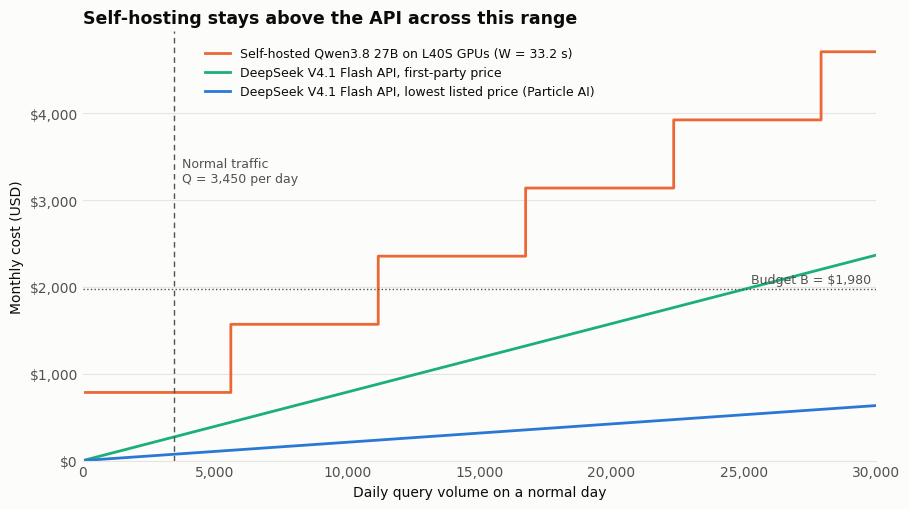

In [11]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
x = np.arange(100, 30001, 25)
low_unit = primary.cost_per_query
first_party_unit = matrix[(matrix.api_price == "DeepSeek first party") & (matrix.plan == "Two-call plan")].iloc[0].cost_per_query

fig, ax = plt.subplots(figsize=(9.2, 5.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(x, self_cost(x, W_self), color=ORANGE, lw=2, drawstyle="steps-post", label=f"Self-hosted Qwen3.8 27B on L40S GPUs (W = {W_self:.1f} s)")
ax.plot(x, month_factor * x * first_party_unit, color=AQUA, lw=2, label="DeepSeek V4.1 Flash API, first-party price")
ax.plot(x, month_factor * x * low_unit, color=BLUE, lw=2, label=f"DeepSeek V4.1 Flash API, lowest listed price ({ds.price_provider})")
ax.axvline(Q, color=MUTED, lw=1, ls=(0, (4, 3)))
ax.annotate(f"Normal traffic\nQ = {Q:,} per day", (Q, 3500), xytext=(6, 0), textcoords="offset points", fontsize=9, color=MUTED, va="top")
ax.axhline(B, color=MUTED, lw=1, ls=":")
ax.annotate(f"Budget B = ${B:,}", (29800, B), xytext=(0, 4), textcoords="offset points", fontsize=9, color=MUTED, ha="right")
ax.set_xlim(0, 30000)
ax.set_ylim(0)
ax.set_xlabel("Daily query volume on a normal day", color=INK)
ax.set_ylabel("Monthly cost (USD)", color=INK)
ax.set_title("Self-hosting stays above the API across this range", loc="left", color=INK, fontsize=12.5, fontweight="bold")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
legend = ax.legend(loc="upper left", bbox_to_anchor=(0.14, 0.99), frameon=False, fontsize=9, labelcolor=INK)
fig.tight_layout()
fig.savefig(HERE / "cost_vs_daily_queries.png", dpi=200, facecolor=SURFACE)
print("Plot saved. Highest self-hosted cost on this plot:", float(self_cost(x, W_self).max()), "| first-party API at 30,000 per day:", round(month_factor * 30000 * first_party_unit, 2))
print("Does the title hold (self-hosting above both API lines across the range)?", bool((self_cost(x, W_self) > month_factor * x * first_party_unit).all()))

In [12]:
(HERE / "q1_results.json").write_text(json.dumps(results, indent=1, default=lambda v: v.item() if hasattr(v, "item") else str(v)), encoding="utf-8")
print("Results saved for the report.")

Results saved for the report.
